In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

Подготовка данных

In [2]:
df = pd.read_csv("bank.csv")
y = df["deposit"].map({"yes": 1, "no": 0})

X = df[["age", "balance"]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print(np.round(X_train[:3], 2))

[[-1.11  1.35]
 [-0.61 -0.37]
 [ 0.57 -0.42]]


Здесь мы выбрали используемые данные. Исследуем зависимсть y (открыл ли депозит) от x (работы и баланса). Данные также переводим в числовое выражение, потому что job и deposit в датасете записаны в текстовом виде. После этого масштабируем признаки.

Оценка точности разных алгоритмов

In [3]:
svm_linear_small = SVC(kernel="linear", C=0.01, gamma="scale", random_state=42)
svm_linear_small.fit(X_train, y_train)

y_pred_lin_small = svm_linear_small.predict(X_test)
acc_lin_small = accuracy_score(y_test, y_pred_lin_small)
print(f"Точность линейного SVM (малый C): {acc_lin_small*100:.1f}%")

Точность линейного SVM (малый C): 53.6%


In [4]:
svm_linear_norm = SVC(kernel="linear", C=1.0, gamma="scale", random_state=42)
svm_linear_norm.fit(X_train, y_train)

y_pred_lin_norm = svm_linear_norm.predict(X_test)
acc_lin_norm = accuracy_score(y_test, y_pred_lin_norm)
print(f"Точность линейного SVM (средний C): {acc_lin_norm*100:.1f}%")

Точность линейного SVM (средний C): 53.7%


In [5]:
svm_linear_big = SVC(kernel="linear", C=10.0, gamma="scale", random_state=42)
svm_linear_big.fit(X_train, y_train)

y_pred_lin_big = svm_linear_big.predict(X_test)
acc_lin_big = accuracy_score(y_test, y_pred_lin_big)
print(f"Точность линейного SVM (большой C): {acc_lin_big*100:.1f}%")

Точность линейного SVM (большой C): 53.7%


Видим, что точность линейного SVM почти неизменна, несмотря на разное значение штрафа. Из этого можно сдлать вывод, что линейное разделение не является идеальным для этого датасета: уже на маленьком значении C алгоритм находит оптимальную линию, и дальнейшее увеличение C её почти не меняет. Можно предположить, что линии лучше не существует. 

In [6]:
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
print(f"Точность SVM (Ядро RBF): {acc_rbf*100:.1f}%")

Точность SVM (Ядро RBF): 61.5%


Алгоритм RBF показал более высокую точность. Достигается это тем, что этот алгоритм умеет огибать признаки кривой линией, поэтому он выделяет их точнее.

Визуализация

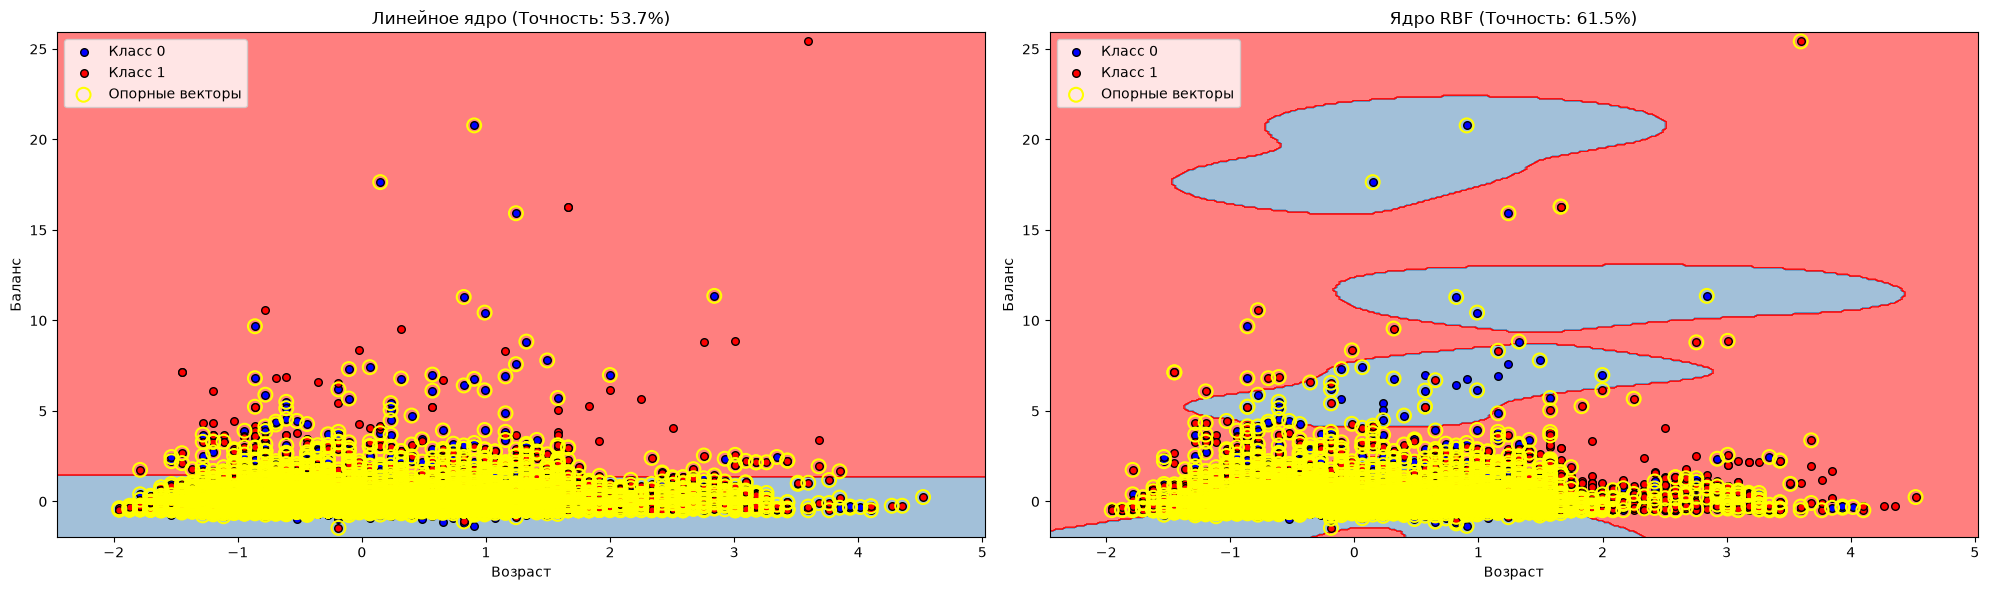

In [7]:
def plot_decision_boundary(model, ax, title):
    X_set, y_set = X_train, y_train
    x1_grid = np.linspace(X_set[:, 0].min() - 0.5, X_set[:, 0].max() + 0.5, 300)
    x2_grid = np.linspace(X_set[:, 1].min() - 0.5, X_set[:, 1].max() + 0.5, 300)
    X1, X2 = np.meshgrid(x1_grid, x2_grid)
    ax.contourf(
        X1,
        X2,
        model.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
        alpha=0.5,
        cmap=ListedColormap(("steelblue", "red")),
    )

    for i, j in enumerate(np.unique(y_set)):
        ax.scatter(
            X_set[y_set == j, 0],
            X_set[y_set == j, 1],
            color=ListedColormap(("blue", "red"))(i),
            label=f"Класс {j}",
            edgecolors="k",
            s=30,
        )

    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        facecolors="none",
        edgecolors="yellow",
        s=100,
        linewidth=1.5,
        label="Опорные векторы",
    )

    ax.set_title(title)
    ax.set_xlabel("Возраст")
    ax.set_ylabel("Баланс")
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(20, 6))

plot_decision_boundary(
    svm_linear_norm, axes[0], f"Линейное ядро (Точность: {acc_lin_norm*100:.1f}%)"
)   
plot_decision_boundary(svm_rbf, axes[1], f"Ядро RBF (Точность: {acc_rbf*100:.1f}%)")

plt.tight_layout()
plt.show()

Видно, что в данных много выбросов, потому что в реальности действително трудно предсказать открытие депозита на основе только данных о возрасте и балансе, ведь у клиентов разные мотивы. RBF-алгоритм справляетмя лучше: он смог выделить несколько областей с концентрацией оьбъектов класса 0. Однако даже он не смог построить оптимальные границы, включающие в себя все выбосы.

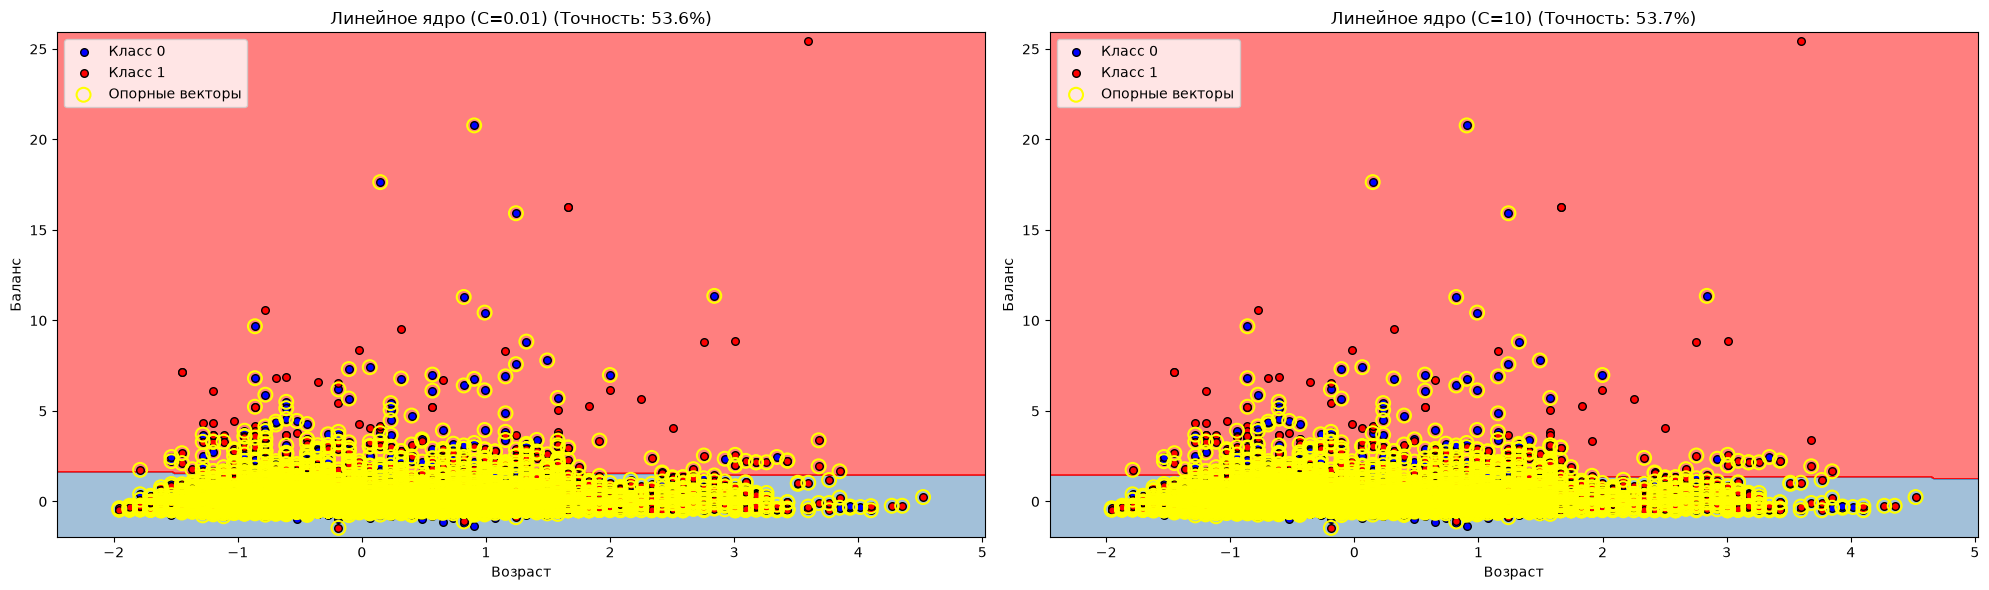

In [9]:
def plot_decision_boundary(model, ax, title):
    X_set, y_set = X_train, y_train
    x1_grid = np.linspace(X_set[:, 0].min() - 0.5, X_set[:, 0].max() + 0.5, 300)
    x2_grid = np.linspace(X_set[:, 1].min() - 0.5, X_set[:, 1].max() + 0.5, 300)
    X1, X2 = np.meshgrid(x1_grid, x2_grid)
    ax.contourf(
        X1,
        X2,
        model.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
        alpha=0.5,
        cmap=ListedColormap(("steelblue", "red")),
    )

    for i, j in enumerate(np.unique(y_set)):
        ax.scatter(
            X_set[y_set == j, 0],
            X_set[y_set == j, 1],
            color=ListedColormap(("blue", "red"))(i),
            label=f"Класс {j}",
            edgecolors="k",
            s=30,
        )

    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        facecolors="none",
        edgecolors="yellow",
        s=100,
        linewidth=1.5,
        label="Опорные векторы",
    )

    ax.set_title(title)
    ax.set_xlabel("Возраст")
    ax.set_ylabel("Баланс")
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(20, 6))

plot_decision_boundary(
    svm_linear_small, axes[0], f"Линейное ядро (C=0.01) (Точность: {acc_lin_small*100:.1f}%)"
)   
plot_decision_boundary(svm_linear_big, axes[1], f"Линейное ядро (C=10) (Точность: {acc_lin_big*100:.1f}%)")

plt.tight_layout()
plt.show()

Видно, что линейный алгоритм в приципе не очень хорошо подходит для этой задачи. Данные очень разрозненно распределены, идеально провести между ними прямую линию не представляется возможным. Уже на низком значении штрафа линия максимально приближена к наивысшей достижимой точности для линейного ядра.